# Real-World Dataset Analysis: Wisconsin Diagnostic Breast Cancer (WDBC)

**Yuva Intern project — Real-World Dataset Analysis Project**

| Field | Value |
|---|---|
| Student name | Lokesh Patwal |
| Internship / program | Data Analyst Intern |
| Organization | Yuva Intern |
| Date | 24 October 2026 |

---
## Section A: Project introduction

**Summary.** This notebook analyses a real clinical dataset: 569 digitised fine-needle-aspirate (FNA) images of breast masses, each described by 30 numeric measurements of the cell nuclei plus a confirmed diagnosis (benign / malignant). The notebook audits the data quality, cleans and preprocesses the data, performs exploratory data analysis with Pandas / NumPy / SciPy, draws charts with Matplotlib / Seaborn and reports findings backed by numbers calculated in the cells below.

**Problem statement.** Which measurable properties of a cell nucleus differ most between benign and malignant breast masses, how strongly do they differ, and what must an analyst know about the data (redundancy between features, skewness, outliers, class balance) before using it for any further modelling?

**Objectives (official project objectives).**
1. Select a real-world dataset from a reliable source and understand its context.
2. Explore the dataset: structure, data types, distributions, missing values, duplicates, relationships.
3. Clean and preprocess: missing values, duplicates, inconsistent data, data types, outliers.
4. Perform exploratory data analysis with Pandas, NumPy and statistics.
5. Create data visualisations (bar, histogram, line, scatter, box, heatmap).
6. Present insights and interpretations in a structured notebook / report.

**Analytical questions.**
- **Q1.** How balanced are the two diagnosis classes?
- **Q2.** How are the individual features distributed (centre, spread, skewness)?
- **Q3.** Which features differ most between malignant and benign cases, and are the differences statistically significant?
- **Q4.** Which features are strongly correlated with each other (redundancy)?
- **Q5.** How does the share of malignant cases change as a key feature increases?
- **Q6.** Where are the outliers, and do they look like errors or like genuine clinical variation?

**Tools.** Python 3, Jupyter Notebook, Pandas, NumPy, Matplotlib, Seaborn, SciPy. Reusable code lives in `src/` (`data_loader.py`, `data_cleaning.py`, `analysis.py`, `visualization.py`) and is unit-tested in `tests/`.

**Dataset source.** *Breast Cancer Wisconsin (Diagnostic)* — W. H. Wolberg, W. N. Street, O. L. Mangasarian (University of Wisconsin; donated to UCI in 1995); UCI Machine Learning Repository, <https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic>, listed there under **CC BY 4.0** (please re-check, see Section J). The copy in `data/raw/` is the file bundled with scikit-learn (`sklearn.datasets.load_breast_cancer`), which is derived from this UCI dataset (see Section J for what this does and does not guarantee).

**Methodology overview.** Load raw data → inspect structure → audit data quality (computed, never assumed) → clean with justified rules (raw file never modified) → EDA with an explicit question for each analysis → visualise → derive findings → conclusions and limitations.

## Section B: Environment and data loading

In [1]:
import sys, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, scipy, matplotlib, seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# Locate the repository root (works when the notebook is started from notebooks/ or from the root).
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import data_loader as dl, data_cleaning as dc, analysis as an, visualization as viz

RAW_PATH  = ROOT / "data" / "raw" / "wdbc_breast_cancer_raw.csv"
PROC_PATH = ROOT / "data" / "processed" / "wdbc_clean.csv"
FIG_DIR   = ROOT / "reports" / "figures"
viz.setup_style()
# Silence a third-party deprecation notice raised inside seaborn 0.13 with matplotlib >= 3.11 (cosmetic only).
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning, module="seaborn")
results = {}   # key numbers are collected here and saved to reports/key_results.json at the end

print("Python    :", platform.python_version())
for m in (np, pd, scipy, matplotlib, sns):
    print(f"{m.__name__:11s}:", m.__version__)
print("Project root:", ROOT.name)

Python    : 3.13.17
numpy      : 2.5.3
pandas     : 3.0.5
scipy      : 1.18.1
matplotlib : 3.11.2
seaborn    : 0.13.2
Project root: real-world-dataset-analysis


In [2]:
try:
    raw = dl.load_raw(RAW_PATH)
    meta = dl.read_metadata(RAW_PATH)
except (FileNotFoundError, ValueError) as exc:
    raise SystemExit(f"Could not load the dataset: {exc}")

print(f"Dataset loaded successfully: {raw.shape[0]} rows x {raw.shape[1]} columns")
print("Class code -> label (from the file header):", dict(enumerate(meta["class_names"])))
results["rows_raw"], results["cols_raw"] = int(raw.shape[0]), int(raw.shape[1])

Dataset loaded successfully: 569 rows x 31 columns
Class code -> label (from the file header): {0: 'malignant', 1: 'benign'}


In [3]:
raw.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
raw.tail()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.256,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.463,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.075,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.595,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,0.3857,1.428,2.548,19.15,0.007189,0.00466,0.00000,0.00000,0.02676,0.002783,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,1


## Section C: Dataset structure

In [5]:
print("Dimensions        :", raw.shape)
print("Columns (31)      :", list(raw.columns))
print()
print("Data types:")
print(raw.dtypes.value_counts().to_string())
num_cols = raw.select_dtypes(include="number").columns.tolist()
cat_cols = raw.select_dtypes(exclude="number").columns.tolist()
print(f"\nNumerical columns : {len(num_cols)}   Text columns: {len(cat_cols)}")
print("Note: 'target' is stored as an integer code (0/1) and is really a categorical label.")

Dimensions        : (569, 31)
Columns (31)      : ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Data types:
float64    30
int64       1

Numerical columns : 31   Text columns: 0
Note: 'target' is stored as an integer code (0/1) and is really a categorical label.


In [6]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "non_null": raw.notna().sum(), "unique_values": raw.nunique()})
info.head(12)

,dtype,non_null,unique_values
mean radius,float64,569,456
mean texture,float64,569,479
mean perimeter,float64,569,522
mean area,float64,569,539
mean smoothness,float64,569,474
mean compactness,float64,569,537
mean concavity,float64,569,537
mean concave points,float64,569,542
mean symmetry,float64,569,432
mean fractal dimension,float64,569,499


In [7]:
print("Unique values of target:", sorted(int(v) for v in raw["target"].unique()))
display(raw.describe().T.round(4))

Unique values of target: [0, 1]


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
mean texture,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
mean perimeter,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
mean area,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
mean smoothness,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
mean compactness,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
mean concavity,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
mean concave points,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
mean symmetry,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040
mean fractal dimension,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974


### Data dictionary

Each record is one digitised FNA image. Ten base properties of the cell nuclei are measured, and each is stored in three forms, which gives 30 numeric columns.

| Base property | Meaning |
|---|---|
| radius | mean distance from the nucleus centre to points on its boundary |
| texture | standard deviation of grey-scale values inside the nucleus |
| perimeter | length of the nucleus boundary |
| area | area of the nucleus |
| smoothness | local variation in radius lengths |
| compactness | perimeter² / area − 1.0 |
| concavity | severity of concave portions of the boundary |
| concave points | number of concave portions of the boundary |
| symmetry | symmetry of the nucleus shape |
| fractal dimension | "coastline approximation" − 1 (boundary roughness) |

| Suffix in the cleaned data | Meaning | Raw column name pattern |
|---|---|---|
| `_mean` | mean over all nuclei in the image | `mean radius` |
| `_se` | standard error over all nuclei in the image | `radius error` |
| `_worst` | mean of the three largest values in the image | `worst radius` |

| Column | Meaning |
|---|---|
| `target` (raw) → `diagnosis` (cleaned) | 0 = Malignant, 1 = Benign in this file; decoded to text labels during cleaning |

The UCI documentation does not state measurement units for the image features, so the notebook reports them as "image-derived units".

## Section D: Data quality audit

Every statement below is computed. Nothing is assumed.

In [8]:
# D1/D2: missing values (all columns) and percentages
miss = dc.missing_report(raw)
print("Total missing cells:", int(miss["missing_count"].sum()), "| columns with any missing:", int((miss["missing_count"] > 0).sum()))
miss.sort_values("missing_count", ascending=False).head(5)

Total missing cells: 0 | columns with any missing: 0


,missing_count,missing_pct
mean radius,0,0.0
mean texture,0,0.0
mean perimeter,0,0.0
mean area,0,0.0
mean smoothness,0,0.0


In [9]:
# D3/D4: duplicates (whole rows, and on the 30 measurement columns only; no ID column exists in this file)
feat_raw = [c for c in raw.columns if c != "target"]
print("Fully duplicated rows            :", dc.duplicate_count(raw))
print("Duplicates on 30 measurement cols:", dc.duplicate_count(raw, subset=feat_raw))
print("Identifier column available      :", any("id" == c.lower() for c in raw.columns))

Fully duplicated rows            : 0
Duplicates on 30 measurement cols: 0
Identifier column available      : False


In [10]:
# D5-D7: data types, invalid values and label consistency (on the renamed columns)
std = dc.standardise_columns(raw)
std_feat = std.drop(columns="target")   # the 30 measurement columns only (target is a label)
print("Non-numeric columns:", std_feat.select_dtypes(exclude="number").columns.tolist())
print("Class codes present :", sorted(int(v) for v in raw["target"].unique()), "| codes defined in header:", list(range(len(meta["class_names"]))))
inv = dc.find_invalid_values(std)
print("Columns violating validity rules (size/texture features > 0, concavity >= 0):", len(inv))
zeros = dc.count_zero_values(std_feat)
print("\nZero values (legitimate for concavity: a perfectly convex outline has none):")
print(zeros.to_string())
zero_rows = (std[["concavity_mean", "concave_points_mean"]] == 0).all(axis=1)
print("\nRows with zero concavity AND zero concave points (mean):", int(zero_rows.sum()))
print("Same rows in all six concavity-type columns?:",
      bool(((std_feat[list(zeros.index)] == 0).sum(axis=1).isin([0, 6])).all()))
results["zero_concavity_rows"] = int(zero_rows.sum())

Non-numeric columns: []
Class codes present : [0, 1] | codes defined in header: [0, 1]
Columns violating validity rules (size/texture features > 0, concavity >= 0): 0

Zero values (legitimate for concavity: a perfectly convex outline has none):
concavity_mean          13
concave_points_mean     13
concavity_se            13
concave_points_se       13
concavity_worst         13
concave_points_worst    13

Rows with zero concavity AND zero concave points (mean): 13
Same rows in all six concavity-type columns?: True


In [11]:
# D7/D10: domain-logic anomaly checks
iso = dc.isoperimetric_violations(std)
print("Rows with perimeter^2 < 4*pi*area (geometrically impossible):", int(iso.sum()))
bases = ["radius","texture","perimeter","area","smoothness","compactness","concavity","concave_points","symmetry","fractal_dimension"]
ok = {b: bool((std[f"{b}_worst"] >= std[f"{b}_mean"]).all()) for b in bases}
print("'worst' >= 'mean' holds for every row in all 10 properties:", all(ok.values()))
print({k: v for k, v in ok.items() if not v} or "no violations")

Rows with perimeter^2 < 4*pi*area (geometrically impossible): 0
'worst' >= 'mean' holds for every row in all 10 properties: True
no violations


In [12]:
# D8: numerical distributions: skewness of every measurement column
sk = std_feat.skew().sort_values(ascending=False)
print("Features with |skew| > 1 :", int((sk.abs() > 1).sum()), "of", len(sk))
sk.head(8).round(2)

Features with |skew| > 1 : 22 of 30


area_se                 5.45
concavity_se            5.11
fractal_dimension_se    3.92
perimeter_se            3.44
radius_se               3.09
smoothness_se           2.31
symmetry_se             2.20
compactness_se          1.90

In [13]:
# D9: potential outliers (Tukey IQR fences, k = 1.5)
mask = dc.iqr_outlier_mask(std_feat)
out_counts = mask.sum().sort_values(ascending=False)
print("Rows with at least one IQR-outlier feature:", int(mask.any(axis=1).sum()), "of", len(std))
print("Features with at least one outlier        :", int((out_counts > 0).sum()), "of", len(out_counts))
out_counts.head(8)

Rows with at least one IQR-outlier feature: 171 of 569
Features with at least one outlier        : 29 of 30


area_se                 65
radius_se               38
perimeter_se            38
area_worst              35
smoothness_se           30
fractal_dimension_se    28
compactness_se          28
symmetry_se             27

### Audit summary

The checks above are summarised in the table below. The results of each check were calculated by the code cells above. Section E documents the action taken for each one.

In [14]:
audit = pd.DataFrame([
    ("Missing values",             int(miss["missing_count"].sum()),             "none found: nothing to impute (imputation would only add noise)"),
    ("Duplicate rows",             dc.duplicate_count(raw),                      "none found: nothing to remove"),
    ("Invalid values (rule-based)", int(inv["violations"].sum()) if len(inv) else 0, "none found"),
    ("Impossible geometry",        int(iso.sum()),                               "none found"),
    ("Non-numeric feature columns", len(std_feat.select_dtypes(exclude="number").columns), "none; label column decoded to text"),
    ("Cryptic column names",       len(raw.columns) - 1,                         "renamed to snake_case with mean / se / worst suffix"),
    ("Rows with >=1 IQR outlier",  int(mask.any(axis=1).sum()),                  "flagged, NOT deleted (see Section E)"),
    ("Strongly skewed features (|skew|>1)", int((sk.abs() > 1).sum()),           "log1p transform evaluated for the worst cases"),
], columns=["Check", "Result (count)", "Action"])
results["audit"] = {r.Check: int(r[1]) for r in audit.itertuples(index=False)}
audit

,Check,Result (count),Action
0,Missing values,0,none found: nothing to impute (imputation woul...
1,Duplicate rows,0,none found: nothing to remove
2,Invalid values (rule-based),0,none found
3,Impossible geometry,0,none found
4,Non-numeric feature columns,0,none; label column decoded to text
5,Cryptic column names,30,renamed to snake_case with mean / se / worst s...
6,Rows with >=1 IQR outlier,171,"flagged, NOT deleted (see Section E)"
7,Strongly skewed features (|skew|>1),22,log1p transform evaluated for the worst cases


## Section E: Data cleaning and preprocessing

In [15]:
clean, log = dc.clean_dataset(raw, meta["class_names"], missing_strategy="report")
before_after = pd.DataFrame({
    "Before (raw)": {"Rows": len(raw), "Columns": raw.shape[1], "Missing cells": int(raw.isna().sum().sum()),
                     "Duplicate rows": dc.duplicate_count(raw), "Rows flagged as outlier": 0},
    "After (clean)": {"Rows": len(clean), "Columns": clean.shape[1], "Missing cells": int(clean.isna().sum().sum()),
                      "Duplicate rows": dc.duplicate_count(clean), "Rows flagged as outlier": int((clean["outlier_feature_count"] > 0).sum())},
})
print(log)
before_after

{'rows_raw': 569, 'cols_raw': 31, 'missing_before': 0, 'missing_after': 0, 'duplicates_removed': 0, 'invalid_value_columns': 0, 'rows_clean': 569, 'cols_clean': 32, 'rows_with_outlier_flag': 171}


,Before (raw),After (clean)
Rows,569,569
Columns,31,32
Missing cells,0,0
Duplicate rows,0,0
Rows flagged as outlier,0,171


In [16]:
print("Cleaned column names:")
print(list(clean.columns))
print("\nDiagnosis dtype:", clean["diagnosis"].dtype, "| categories:", list(clean["diagnosis"].cat.categories))
clean[["diagnosis", "radius_mean", "area_mean", "concave_points_worst", "outlier_feature_count"]].head()

Cleaned column names:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'diagnosis', 'outlier_feature_count']

Diagnosis dtype: category | categories: ['Malignant', 'Benign']


,diagnosis,radius_mean,area_mean,concave_points_worst,outlier_feature_count
0,Malignant,17.99,1001.0,0.2654,8
1,Malignant,20.57,1326.0,0.1860,1
2,Malignant,19.69,1203.0,0.2430,1
3,Malignant,11.42,386.1,0.2575,11
4,Malignant,20.29,1297.0,0.1625,1


### Cleaning decisions

| Problem | How it was identified | Method selected | Why | Result |
|---|---|---|---|---|
| Cryptic names (`mean concave points`, `area error`) | Column listing | Rename to snake_case with `_mean` / `_se` / `_worst` | Easier to read and select programmatically | 30 columns renamed |
| Label stored as integer code | `dtypes` + file header | Decode to categorical `diagnosis` (Malignant / Benign) | Readable charts and grouping; code → label map comes from the file header | 569 labels decoded, none unknown |
| Missing values | `missing_report` | Strategy `"report"` (no change) | The audit found no missing cells; filling or dropping would alter genuine data | 0 before, 0 after |
| Duplicate rows | `duplicated()` on all columns and on the 30 measurements | Remove only if found | Exact duplicates would double-count patients | 0 removed |
| Invalid values / impossible geometry | Rule checks (positivity, `perimeter² ≥ 4πA`, `worst ≥ mean`) | Remove only if found | Would indicate entry errors | none found |
| Outliers | IQR (Tukey) fences on every feature | **Flag** with `outlier_feature_count`; **keep** all rows | Large nuclei are exactly what malignancy looks like; deleting them would remove the signal being studied (Section F, Q6) | Flag column added |
| Skewed features | `skew()` | Evaluate `log1p` for visualisation / modelling; keep the original values in the saved file | Original units stay interpretable | see Q2 |

The raw CSV is never modified: every cleaning function returns a new object.

In [17]:
PROC_PATH.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(PROC_PATH, index=False)
check = pd.read_csv(PROC_PATH)
print("Saved:", PROC_PATH.relative_to(ROOT), "| shape on disk:", check.shape)
print("Raw file untouched (reload equals the first load):", raw.equals(dl.load_raw(RAW_PATH)))
results.update(rows_clean=int(len(clean)), cols_clean=int(clean.shape[1]),
               rows_flagged_outlier=int((clean["outlier_feature_count"] > 0).sum()))

Saved: data/processed/wdbc_clean.csv | shape on disk: (569, 32)
Raw file untouched (reload equals the first load): True


## Section F: Exploratory data analysis

Each analysis starts from one question, shows the code and output, and ends with an interpretation and its limits. Time-based trends were **not** analysed because the dataset contains no date or time variable.

### Q1. How balanced are the two diagnosis classes?

In [18]:
balance = an.class_balance(clean)
print("Mode of diagnosis:", clean["diagnosis"].mode().iloc[0])
results["n_benign"]    = int(balance.loc["Benign", "count"]);    results["pct_benign"]    = float(balance.loc["Benign", "percent"])
results["n_malignant"] = int(balance.loc["Malignant", "count"]); results["pct_malignant"] = float(balance.loc["Malignant", "percent"])
balance

Mode of diagnosis: Benign


,count,percent
diagnosis,,
Benign,357,62.74
Malignant,212,37.26


**Interpretation.** The dataset contains 357 benign (62.74%) and 212 malignant (37.26%) records, a ratio of about 1.7 : 1. The imbalance is mild, so both classes have enough records for the group comparisons below. The most frequent class (mode) is *Benign*.

**Significance and limitation.** A trivial rule that always answers "benign" would be right 62.74% of the time, so any later predictive use must beat that baseline and should report class-wise metrics rather than accuracy alone. This is the class mix of *this* sample; it is not the prevalence of cancer in the general population.

### Q2. How are the features distributed (centre, spread, skewness)?

In [19]:
mean_cols = [c for c in dc.feature_columns(clean) if c.endswith("_mean")]
desc = an.describe_numeric(clean, mean_cols)
display(desc.round(5))
print("Coefficient of variation (std / mean), %:")
(desc["std"] / desc["mean"] * 100).round(1).sort_values(ascending=False)

Coefficient of variation (std / mean), %:


,mean,median,std,variance,min,q1,q3,max,skew,kurtosis
radius_mean,14.12729,13.37000,3.52405,12.41892,6.98100,11.70000,15.78000,28.11000,0.94238,0.84552
texture_mean,19.28965,18.84000,4.30104,18.49891,9.71000,16.17000,21.80000,39.28000,0.65045,0.75832
perimeter_mean,91.96903,86.24000,24.29898,590.44048,43.79000,75.17000,104.10000,188.50000,0.99065,0.97221
area_mean,654.88910,551.10000,351.91413,123843.55432,143.50000,420.30000,782.70000,2501.00000,1.64573,3.65230
smoothness_mean,0.09636,0.09587,0.01406,0.00020,0.05263,0.08637,0.10530,0.16340,0.45632,0.85597
compactness_mean,0.10434,0.09263,0.05281,0.00279,0.01938,0.06492,0.13040,0.34540,1.19012,1.65013
concavity_mean,0.08880,0.06154,0.07972,0.00636,0.00000,0.02956,0.13070,0.42680,1.40118,1.99864
concave_points_mean,0.04892,0.03350,0.03880,0.00151,0.00000,0.02031,0.07400,0.20120,1.17118,1.06656
symmetry_mean,0.18116,0.17920,0.02741,0.00075,0.10600,0.16190,0.19570,0.30400,0.72561,1.28793
fractal_dimension_mean,0.06280,0.06154,0.00706,0.00005,0.04996,0.05770,0.06612,0.09744,1.30449,3.00589


concavity_mean            89.8
concave_points_mean       79.3
area_mean                 53.7
compactness_mean          50.6
perimeter_mean            26.4
radius_mean               24.9
texture_mean              22.3
symmetry_mean             15.1
smoothness_mean           14.6
fractal_dimension_mean    11.2

In [20]:
# Skewness before / after log(1 + x) for the five most skewed features
all_feat = dc.feature_columns(clean)
top_skew = clean[all_feat].skew().sort_values(ascending=False).head(5).index.tolist()
skew_tbl = an.skew_before_after_log(clean, top_skew).round(2)
results["skew_area_se_raw"]  = float(skew_tbl.loc["area_se", "skew_raw"])
results["skew_area_se_log"]  = float(skew_tbl.loc["area_se", "skew_log1p"])
skew_tbl

,skew_raw,skew_log1p
feature,,
area_se,5.45,0.85
concavity_se,5.11,4.23
fractal_dimension_se,3.92,3.87
perimeter_se,3.44,1.03
radius_se,3.09,1.71


**Interpretation.** For the size features the mean is above the median (e.g. `radius_mean`: mean 14.13 vs median 13.37; `area_mean`: 654.89 vs 551.10), and the positive skewness values (0.94 and 1.65) confirm a right-skewed shape: most nuclei are small and a minority are very large. Relative spread (coefficient of variation) is largest for the shape-irregularity features `concavity_mean` (89.8%) and `concave_points_mean` (79.3%) and smallest for `fractal_dimension_mean` (11.2%) and `smoothness_mean` (14.6%).

The audit found 22 of 30 features with |skew| > 1. A `log(1 + x)` transform helps strongly where values are large relative to their spread (`area_se` 5.45 → 0.85, `perimeter_se` 3.44 → 1.03, `radius_se` 3.09 → 1.71) but barely helps where values are tiny, because `log(1 + x) ≈ x` when x is close to 0 (`concavity_se` 5.11 → 4.23, `fractal_dimension_se` 3.92 → 3.87).

**Significance and limitation.** Skewness matters for methods that assume symmetric data, so the original values are kept in the saved file and a transform is applied only when needed. This is why the group tests in Q3 use the rank-based Mann-Whitney U test, which does not assume normality.

### Q3. Which features differ most between malignant and benign cases?

In [21]:
cmp = an.compare_groups(clean, all_feat)
n_sig  = int((cmp["mannwhitney_p"] < 0.05).sum())
n_bonf = int((cmp["mannwhitney_p"] < 0.05 / len(cmp)).sum())
print(f"Features tested: {len(cmp)} | significant at p < 0.05: {n_sig} | after Bonferroni (p < {0.05/len(cmp):.4f}): {n_bonf}")
print("Not significant:", cmp.index[cmp["mannwhitney_p"] >= 0.05].tolist())
results.update(n_features_tested=int(len(cmp)), n_sig=n_sig, n_sig_bonferroni=n_bonf)
cols = ["mean_malignant", "mean_benign", "pct_diff_of_means", "cohens_d", "separation_auc", "mannwhitney_p"]
cmp[cols].head(10).round(4)

Features tested: 30 | significant at p < 0.05: 27 | after Bonferroni (p < 0.0017): 26
Not significant: ['smoothness_se', 'fractal_dimension_mean', 'texture_se']


,mean_malignant,mean_benign,pct_diff_of_means,cohens_d,separation_auc,mannwhitney_p
feature,,,,,,
perimeter_worst,141.3703,87.0059,62.4835,2.5982,0.9755,0.0
radius_worst,21.1348,13.3798,57.9606,2.5439,0.9704,0.0
area_worst,1422.2863,558.8994,154.4798,2.2302,0.9698,0.0
concave_points_worst,0.1822,0.0744,144.7967,2.6926,0.9667,0.0
concave_points_mean,0.0880,0.0257,242.1418,2.5452,0.9644,0.0
perimeter_mean,115.3654,78.0754,47.7615,2.2895,0.9469,0.0
area_mean,978.3764,462.7902,111.4082,2.0757,0.9383,0.0
concavity_mean,0.1608,0.0461,249.0730,2.0033,0.9378,0.0
radius_mean,17.4628,12.1465,43.7681,2.2055,0.9375,0.0


**Interpretation.** Malignant records have markedly larger values for the size and shape features. For example, `perimeter_worst` averages 141.37 in malignant cases vs 87.01 in benign cases (+62.5%), with Cohen's d = 2.60 (a very large effect) and a separation AUC of 0.975: in 97.5% of random malignant-vs-benign pairs the malignant record has the larger value. `concave_points_worst` has the largest effect size (d = 2.69; 0.182 vs 0.074).

27 of the 30 features differ significantly (Mann-Whitney U, p < 0.05), and 26 remain significant after a Bonferroni correction for 30 tests (p < 0.0017). The three features with no significant difference are `smoothness_se`, `fractal_dimension_mean` and `texture_se`. The p-values display as 0.0 only because of rounding to four decimals.

**Significance and limitation.** Statistical significance is not clinical usefulness, and the 30 features are strongly inter-correlated (see Q4), so the 30 tests are not independent. Bonferroni is conservative. The comparison shows association within this sample, not causation.

### Q4. Which features are strongly correlated with each other?

In [22]:
pairs_mean = an.top_correlated_pairs(clean, mean_cols, threshold=0.9)
pairs_all  = an.top_correlated_pairs(clean, all_feat, threshold=0.9)
print("Pairs with |r| >= 0.9 among the 10 mean features:", len(pairs_mean))
print("Pairs with |r| >= 0.9 among all 30 features     :", len(pairs_all), "of", len(all_feat) * (len(all_feat) - 1) // 2)
results["pairs_r09_mean"] = int(len(pairs_mean)); results["pairs_r09_all"] = int(len(pairs_all))
results["r_radius_perimeter"] = float(clean["radius_mean"].corr(clean["perimeter_mean"]))
results["r_radius_area"]      = float(clean["radius_mean"].corr(clean["area_mean"]))
pairs_mean.round(4)

Pairs with |r| >= 0.9 among the 10 mean features: 4
Pairs with |r| >= 0.9 among all 30 features     : 21 of 435


,feature_1,feature_2,pearson_r
0,radius_mean,perimeter_mean,0.9979
1,radius_mean,area_mean,0.9874
2,perimeter_mean,area_mean,0.9865
3,concavity_mean,concave_points_mean,0.9214


In [23]:
corr_dx = an.correlation_with_diagnosis(clean, all_feat)
print("Correlation of each feature with 'is malignant' (point-biserial), strongest 6:")
corr_dx.head(6).round(3)

Correlation of each feature with 'is malignant' (point-biserial), strongest 6:


concave_points_worst    0.794
perimeter_worst         0.783
concave_points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734

**Interpretation.** `radius_mean`, `perimeter_mean` and `area_mean` are almost perfectly correlated (radius–perimeter r = 0.998, radius–area r = 0.987, perimeter–area r = 0.987), and `concavity_mean` with `concave_points_mean` reaches r = 0.921. Across all 30 features, 21 of the 435 possible pairs have |r| ≥ 0.9. This is expected geometrically: perimeter and area are functions of the radius. The strongest single correlations with being malignant are `concave_points_worst` (r = 0.794), `perimeter_worst` (0.783), `concave_points_mean` (0.777) and `radius_worst` (0.776).

**Significance and limitation.** The three size features carry nearly the same information, so an analysis or model should keep one of them rather than all three (otherwise multicollinearity makes coefficients unstable and inflates apparent importance). Pearson r measures linear association only and does not imply causation.

### Q5. How does the share of malignant cases change as a key feature increases?

In [24]:
rate = an.rate_by_quantile_bin(clean, "concave_points_worst", q=10)
rate["decile"] = range(1, len(rate) + 1)
print("Malignant share in lowest 4 deciles :", f"{rate.loc[:3, 'malignant_count'].sum()} of {rate.loc[:3, 'n'].sum()}")
print("Malignant share in highest 3 deciles:", f"{rate.loc[7:, 'malignant_count'].sum()} of {rate.loc[7:, 'n'].sum()}")
results["low4_mal"], results["low4_n"] = int(rate.loc[:3, "malignant_count"].sum()), int(rate.loc[:3, "n"].sum())
results["high3_mal"], results["high3_n"] = int(rate.loc[7:, "malignant_count"].sum()), int(rate.loc[7:, "n"].sum())
rate.round(3)

Malignant share in lowest 4 deciles : 4 of 228
Malignant share in highest 3 deciles: 165 of 171


,bin_mean,n,malignant_count,malignant_rate_pct,decile
0,0.020,58,1,1.724,1
1,0.050,56,0,0.000,2
2,0.065,57,2,3.509,3
3,0.079,57,1,1.754,4
4,0.091,57,5,8.772,5
5,0.110,58,12,20.690,6
6,0.138,55,26,47.273,7
7,0.163,57,51,89.474,8
8,0.193,57,57,100.000,9
9,0.239,57,57,100.000,10


**Interpretation.** The share of malignant cases rises steeply with `concave_points_worst`. In the lowest four deciles only 4 of 228 records (1.8%) are malignant. The rate then climbs through deciles 6–8 (20.7%, 47.3%, 89.5%) and reaches 100% in deciles 9 and 10. In the highest three deciles, 165 of 171 records (96.5%) are malignant. The transition happens between roughly 0.11 and 0.16.

**Significance and limitation.** This shows the dataset has a clear dose-response-like pattern, which is why this feature ranks at the top in Q3. These rates are specific to this sample: because the sample contains 37% malignant cases, the same cut-offs would not give the same rates in a population with lower prevalence. Deciles are descriptive bins, not a validated diagnostic rule.

### Q6. Where are the outliers, and are they errors or genuine variation?

In [25]:
mask_c = dc.iqr_outlier_mask(clean)
by_class = clean.assign(flagged=clean["outlier_feature_count"] > 0).groupby("diagnosis", observed=True).agg(
    rows=("flagged", "size"), rows_flagged=("flagged", "sum"),
    pct_flagged=("flagged", lambda s: s.mean() * 100),
    mean_outlier_features=("outlier_feature_count", "mean"))
print("Top features by number of IQR outliers:")
display(mask_c.sum().sort_values(ascending=False).head(6))
for k in ("Malignant", "Benign"):
    results[f"pct_flagged_{k.lower()}"] = float(by_class.loc[k, "pct_flagged"])
    results[f"mean_outliers_{k.lower()}"] = float(by_class.loc[k, "mean_outlier_features"])
results["max_outlier_features_in_row"] = int(clean["outlier_feature_count"].max())
by_class.round(2)

Top features by number of IQR outliers:


area_se                 65
radius_se               38
perimeter_se            38
area_worst              35
smoothness_se           30
fractal_dimension_se    28

,rows,rows_flagged,pct_flagged,mean_outlier_features
diagnosis,,,,
Malignant,212,114,53.77,2.21
Benign,357,57,15.97,0.39


**Interpretation.** 171 of 569 records (30.1%) have at least one feature outside the IQR fences. The flags are highly concentrated in malignant cases: 114 of 212 malignant records (53.8%) vs 57 of 357 benign records (16.0%), and on average 2.21 vs 0.39 outlier features per record; one record has 18 outlier features. The features with the most outliers are `area_se` (65), `radius_se` (38), `perimeter_se` (38) and `area_worst` (35).

These records are **not** treated as errors: they pass every validity check in Section D (positive sizes, no impossible geometry, `worst ≥ mean` everywhere), and their concentration in the malignant class shows that extreme size is part of the signal. Deleting them would remove a large part of the malignant class and bias every later result, so they are flagged (`outlier_feature_count`) and kept.

**Significance and limitation.** The IQR rule assumes a roughly symmetric distribution; for right-skewed features it flags the upper tail more often than a symmetric rule would. A flag means "statistically unusual", not "wrong".

## Section G: Data visualisation

All charts use the real cleaned data and are saved to `reports/figures/`. Colours are fixed per class (Benign = blue, Malignant = orange).

### Figure 1: Bar chart: diagnosis counts

saved -> reports/figures/fig01_class_bar.png


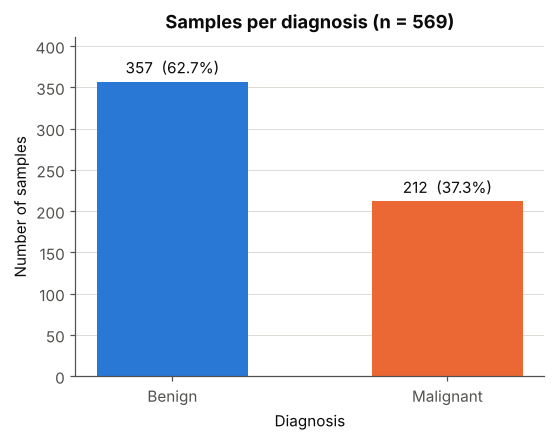

In [26]:
p = viz.plot_class_bar(clean, FIG_DIR / "fig01_class_bar.png")
print("saved ->", p.relative_to(ROOT))

**Interpretation.** The bars match the table in Q1: 357 benign records (62.7%) and 212 malignant records (37.3%) out of 569. The benign class is about 1.7 times larger; the imbalance is visible but not extreme.

### Figure 2: Histogram: mean radius by diagnosis

saved -> reports/figures/fig02_hist_radius_mean.png


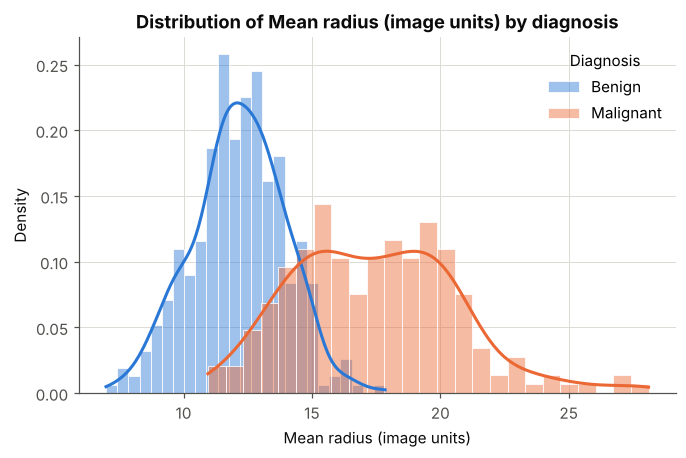

In [27]:
p = viz.plot_hist_by_class(clean, "radius_mean", FIG_DIR / "fig02_hist_radius_mean.png", "Mean radius (image units)")
print("saved ->", p.relative_to(ROOT))

**Interpretation.** The two class distributions are clearly shifted: the mean radius is 12.15 for benign and 17.46 for malignant records. The curves overlap in the middle range, which is why mean radius alone does not separate the classes perfectly (separation AUC = 0.938). The long right tail of the malignant class matches the right skew seen in Q2.

### Figure 3: Line chart: malignant share across bins of worst concave points

saved -> reports/figures/fig03_line_malignant_rate.png


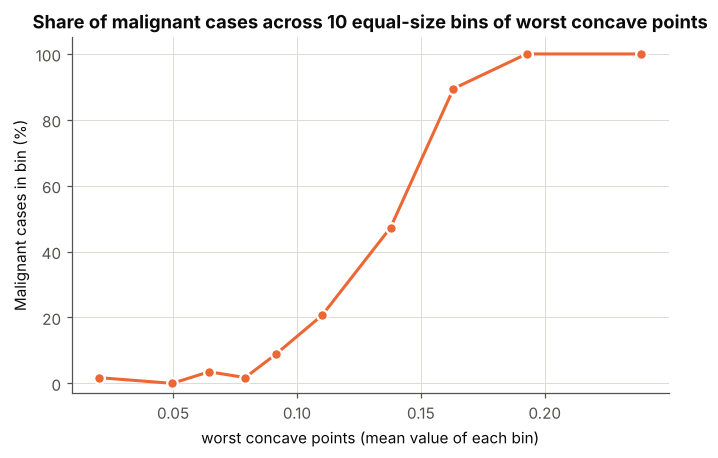

In [28]:
p = viz.plot_rate_line(rate, "worst concave points", FIG_DIR / "fig03_line_malignant_rate.png")
print("saved ->", p.relative_to(ROOT))

**Interpretation.** The line is almost flat near 0–9% for the five lowest bins (1.7%, 0.0%, 3.5%, 1.8%, 8.8%), then rises steeply (20.7%, 47.3%, 89.5%) and stays at 100% for the two highest bins. The bin points are equal-frequency bins, so each point is based on 55–58 records. This chart shows the same pattern as the Q5 table.

### Figure 4: Scatter plot: mean radius vs mean concave points

saved -> reports/figures/fig04_scatter_radius_vs_concave.png


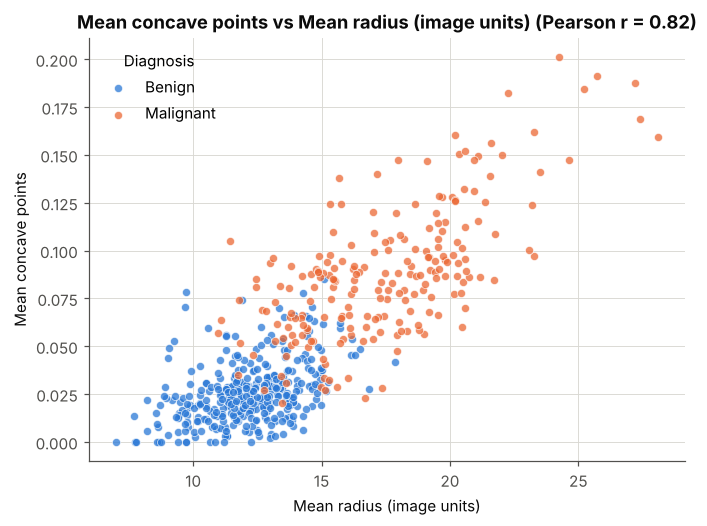

In [29]:
p = viz.plot_scatter(clean, "radius_mean", "concave_points_mean", FIG_DIR / "fig04_scatter_radius_vs_concave.png", "Mean radius (image units)", "Mean concave points")
print("saved ->", p.relative_to(ROOT))

**Interpretation.** Radius and concave points are positively related (r = 0.82 over all records). Benign records (blue) cluster at small radius and few concave points; malignant records (orange) spread toward the upper right. The two groups mix in the middle (roughly radius 12–18), which is where a single feature cannot decide the class. The correlation is computed over both classes together, so part of it simply reflects the class difference.

### Figure 5: Box plots: four key features by diagnosis

saved -> reports/figures/fig05_boxplots_key_features.png


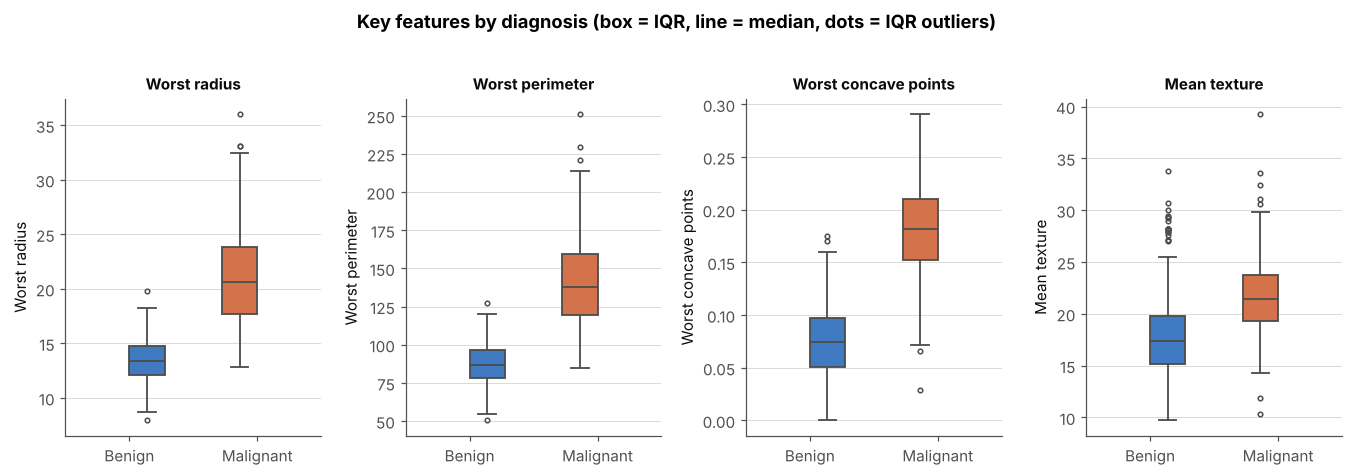

In [30]:
p = viz.plot_boxplots(clean, ["radius_worst", "perimeter_worst", "concave_points_worst", "texture_mean"], ["Worst radius", "Worst perimeter", "Worst concave points", "Mean texture"], FIG_DIR / "fig05_boxplots_key_features.png")
print("saved ->", p.relative_to(ROOT))

**Interpretation.** For worst radius, worst perimeter and worst concave points the middle 50% of benign values (boxes) lies clearly below that of malignant values, with little or no box overlap; this agrees with the large effect sizes (d between 2.5 and 2.7) in Q3. Mean texture overlaps far more. The dots show that the benign class has many high-texture outliers, while the malignant class has the longest upper whiskers for the size features.

### Figure 6: Correlation heatmap of the 10 mean features

saved -> reports/figures/fig06_corr_heatmap.png


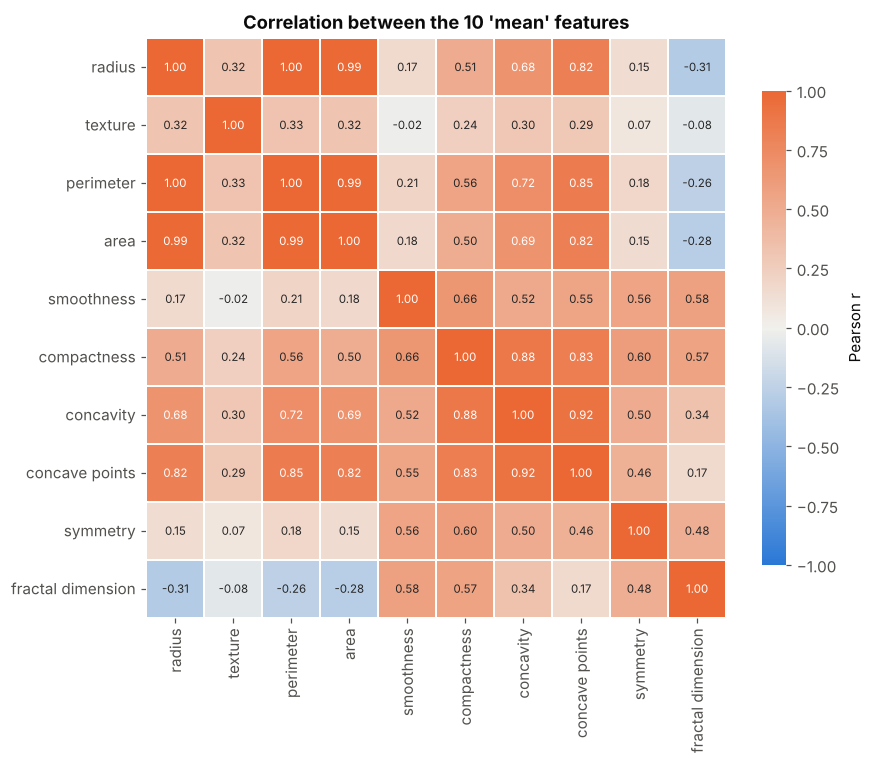

In [31]:
p = viz.plot_corr_heatmap(clean, mean_cols, [c.replace("_mean", "").replace("_", " ") for c in mean_cols], FIG_DIR / "fig06_corr_heatmap.png")
print("saved ->", p.relative_to(ROOT))

**Interpretation.** Radius, perimeter and area form a block of near-perfect correlation (1.00 / 0.99), and concavity, concave points and compactness form a second block (0.83–0.92). Texture is only weakly related to the size features (r = 0.32 with radius). Fractal dimension is the only feature with negative correlations with size (−0.26 to −0.31). The heatmap supports the redundancy finding from Q4.

### Figure 7: Bar chart: separation AUC of all 30 features

saved -> reports/figures/fig07_feature_auc.png


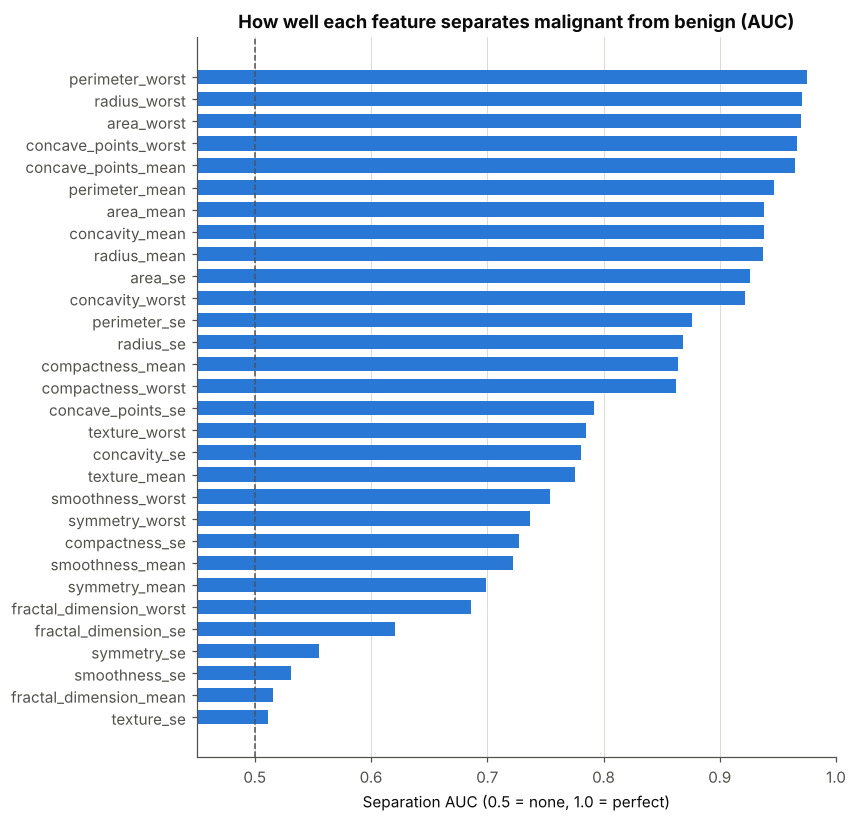

In [32]:
p = viz.plot_auc_bar(cmp, FIG_DIR / "fig07_feature_auc.png")
print("saved ->", p.relative_to(ROOT))

**Interpretation.** The best-separating features are the 'worst' size features (`perimeter_worst` 0.975, `radius_worst` 0.970, `area_worst` 0.970) followed by concave-point features. The three weakest are `texture_se` (0.512), `fractal_dimension_mean` (0.515) and `smoothness_se` (0.531), close to the 0.5 'no separation' line, matching the three non-significant features in Q3.

### Figure 8: Histograms: area_se before / after log(1 + x)

saved -> reports/figures/fig08_skew_area_se.png


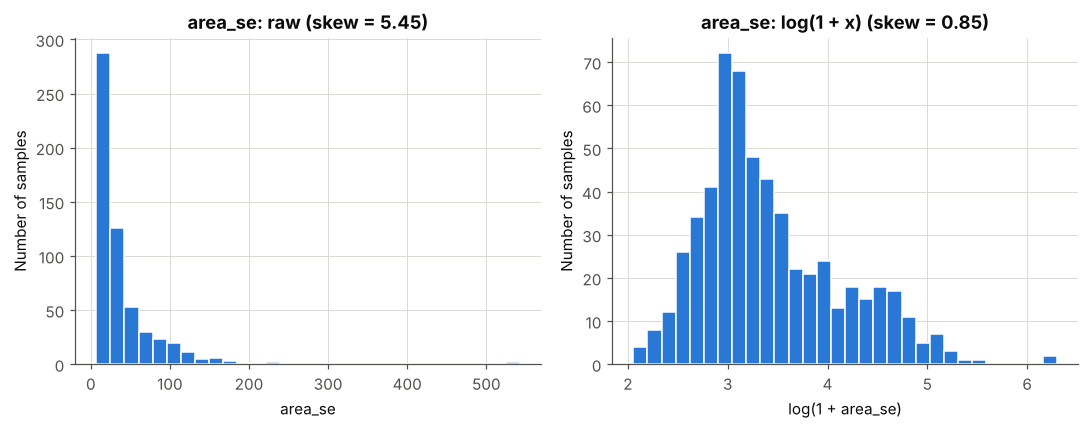

In [33]:
p = viz.plot_skew_before_after(clean, "area_se", FIG_DIR / "fig08_skew_area_se.png", "area_se")
print("saved ->", p.relative_to(ROOT))

**Interpretation.** Raw `area_se` is strongly right-skewed (skewness 5.45), with a single extreme value above 500 stretching the axis. After `log(1 + x)` the distribution is much closer to symmetric (skewness 0.85). The saved dataset keeps the raw values; the transformed version is for analysis or modelling that requires symmetry.

### Figure 9: Bar chart: features with most IQR outliers

saved -> reports/figures/fig09_outlier_counts.png


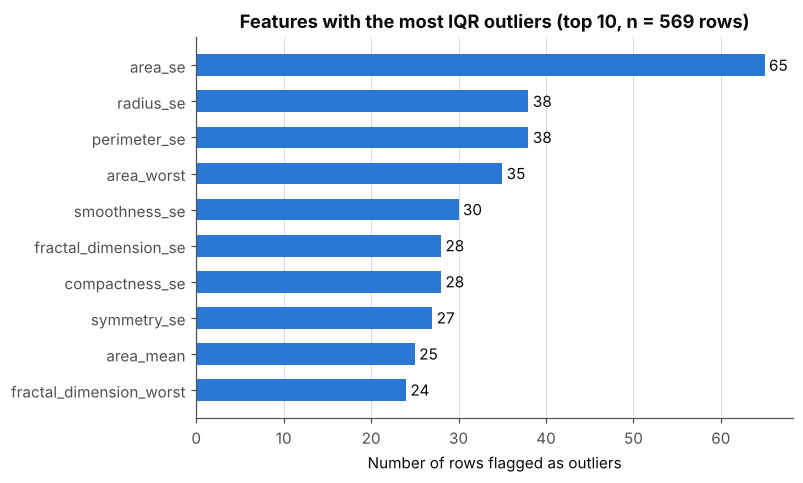

In [34]:
p = viz.plot_outlier_counts(mask_c.sum(), FIG_DIR / "fig09_outlier_counts.png", len(clean))
print("saved ->", p.relative_to(ROOT))

**Interpretation.** Most of the features with many outliers are standard-error (`_se`) features, led by `area_se` with 65 flagged rows. These are the most skewed features (Section D), so the IQR rule flags many upper-tail values. This fits the explanation in Q6 that the flags reflect a skewed distribution and genuine large nuclei rather than data-entry errors.

## Section H: Findings and insights

Each finding below is computed from the data in the cell and tied to a table or figure above.

In [35]:
f = {}
# Finding 1: class balance
f[1] = (f"Benign {results['n_benign']} ({results['pct_benign']:.2f}%) vs Malignant {results['n_malignant']} ({results['pct_malignant']:.2f}%)")
# Finding 2: size / shape features separate the classes
top = cmp.iloc[0]
f[2] = (f"{cmp.index[0]}: malignant mean {top['mean_malignant']:.2f} vs benign {top['mean_benign']:.2f} "
        f"({top['pct_diff_of_means']:+.1f}%), Cohen's d = {top['cohens_d']:.2f}, separation AUC = {top['separation_auc']:.3f}; "
        f"{results['n_sig']} of {results['n_features_tested']} features differ at p<0.05 ({results['n_sig_bonferroni']} after Bonferroni)")
# Finding 3: redundancy
f[3] = (f"r(radius_mean, perimeter_mean) = {results['r_radius_perimeter']:.3f}; r(radius_mean, area_mean) = {results['r_radius_area']:.3f}; "
        f"{results['pairs_r09_all']} of 435 feature pairs have |r| >= 0.9")
# Finding 4: dose-response
f[4] = (f"lowest 4 deciles of worst concave points: {results['low4_mal']} malignant of {results['low4_n']} "
        f"({results['low4_mal']/results['low4_n']*100:.1f}%); highest 3 deciles: {results['high3_mal']} of {results['high3_n']} "
        f"({results['high3_mal']/results['high3_n']*100:.1f}%)")
# Finding 5: outliers concentrate in malignant cases
f[5] = (f"{results['rows_flagged_outlier']} of {results['rows_clean']} rows ({results['rows_flagged_outlier']/results['rows_clean']*100:.1f}%) have >=1 outlier feature; "
        f"flagged share: malignant {results['pct_flagged_malignant']:.1f}% vs benign {results['pct_flagged_benign']:.1f}%; "
        f"mean outlier features per row: malignant {results['mean_outliers_malignant']:.2f} vs benign {results['mean_outliers_benign']:.2f}")
# Finding 6: skewness and weak features
weak = cmp.sort_values("separation_auc").head(3)
f[6] = (f"area_se skewness {results['skew_area_se_raw']:.2f} -> {results['skew_area_se_log']:.2f} after log1p; weakest features: "
        + ", ".join(f"{i} (AUC {r.separation_auc:.3f})" for i, r in weak.iterrows()))
for k, v in f.items():
    print(f"FINDING {k}: {v}\n")
results["findings"] = {str(k): v for k, v in f.items()}

FINDING 1: Benign 357 (62.74%) vs Malignant 212 (37.26%)

FINDING 2: perimeter_worst: malignant mean 141.37 vs benign 87.01 (+62.5%), Cohen's d = 2.60, separation AUC = 0.975; 27 of 30 features differ at p<0.05 (26 after Bonferroni)

FINDING 3: r(radius_mean, perimeter_mean) = 0.998; r(radius_mean, area_mean) = 0.987; 21 of 435 feature pairs have |r| >= 0.9

FINDING 4: lowest 4 deciles of worst concave points: 4 malignant of 228 (1.8%); highest 3 deciles: 165 of 171 (96.5%)

FINDING 5: 171 of 569 rows (30.1%) have >=1 outlier feature; flagged share: malignant 53.8% vs benign 16.0%; mean outlier features per row: malignant 2.21 vs benign 0.39

FINDING 6: area_se skewness 5.45 -> 0.85 after log1p; weakest features: texture_se (AUC 0.512), fractal_dimension_mean (AUC 0.515), smoothness_se (AUC 0.531)



### Finding 1: Mild class imbalance
**Statement.** 62.74% of the records are benign and 37.26% malignant. **Evidence.** 357 benign vs 212 malignant (Q1 table, Figure 1). **Implication.** Report class-wise results; the "always benign" baseline is 62.74%. **Limitation.** Reflects this sample, not population prevalence.

### Finding 2: Size and concavity features separate malignant from benign strongly
**Statement.** The top feature, `perimeter_worst`, averages 141.37 (malignant) vs 87.01 (benign), +62.5%, Cohen's d = 2.60, AUC = 0.975. `concave_points_worst` has the largest effect size (d = 2.69). 27 of 30 features differ at p < 0.05 and 26 after Bonferroni. **Evidence.** Q3 table, Figures 5 and 7. **Implication.** These features are the most informative candidates for any further analysis. **Limitation.** Significance is not clinical validity; tests are not independent.

### Finding 3: The size features are almost redundant
**Statement.** r(radius, perimeter) = 0.998 and r(radius, area) = 0.987; 21 of 435 feature pairs have |r| ≥ 0.9. **Evidence.** Q4 tables, Figure 6. **Implication.** Use one size feature (or reduce dimensions) to avoid multicollinearity. **Limitation.** Pearson r is linear and not causal.

### Finding 4: Malignancy rate jumps sharply with worst concave points
**Statement.** 4 of 228 records (1.8%) in the lowest four deciles are malignant vs 165 of 171 (96.5%) in the highest three deciles. **Evidence.** Q5 table, Figure 3. **Implication.** A clear threshold region (about 0.11–0.16) exists in this sample. **Limitation.** Rates depend on the 37% malignant share of this sample and are not a validated diagnostic rule.

### Finding 5: Outliers are concentrated in malignant cases and are genuine variation
**Statement.** 171 of 569 records (30.1%) have ≥ 1 outlier feature: 53.8% of malignant vs 16.0% of benign records (2.21 vs 0.39 outlier features per record). All pass the validity checks. **Evidence.** Q6 table, Figures 5 and 9. **Implication.** Deleting outliers would damage the malignant class; they are flagged and kept. **Limitation.** The IQR rule over-flags in skewed features.

### Finding 6: Several features are heavily skewed, and three carry no class signal
**Statement.** 22 of 30 features have |skew| > 1; `log(1 + x)` reduces `area_se` skewness from 5.45 to 0.85 but barely changes `fractal_dimension_se` (3.92 → 3.87). `texture_se`, `fractal_dimension_mean` and `smoothness_se` show no significant class difference (AUC 0.512, 0.515, 0.531). **Evidence.** Q2 and Q3 tables, Figures 7 and 8. **Implication.** Choose transformations per feature; weak features can be dropped without losing class information. **Limitation.** A feature with no marginal effect might still help in combination with others, which this analysis did not test.

## Section I: Conclusion and recommendations

**What was investigated.** Which measurable nucleus properties differ between benign and malignant breast masses in the 569-record WDBC dataset, and what an analyst must know about the data quality before using it.

**What was discovered.** The data are very clean (0 missing values, 0 duplicates, 0 invalid or impossible values). Malignant records have much larger size and concavity measurements (`perimeter_worst` +62.5%, d = 2.60); 27 of 30 features differ significantly; the size features are almost redundant (r up to 0.998); the malignant share rises from 1.8% to 96.5% between the lowest and highest ranges of `concave_points_worst`; and 30.1% of records contain outlier values that are concentrated in malignant cases and are genuine.

**Recommendations supported by the evidence.**
1. Keep the outlier records; flag rather than delete them (Finding 5).
2. Use only one of radius / perimeter / area, or a dimensionality-reduction step, in any later model (Finding 3).
3. Prioritise the 'worst' size features and the concave-point features, and consider dropping the three non-significant features (Findings 2 and 6).
4. Apply `log(1 + x)` only where it reduces skewness (e.g. `area_se`), not to features with tiny values (Finding 6).
5. Report class-wise performance, not accuracy alone, because of the 62.74% / 37.26% class split (Finding 1).

**What the analysis cannot establish.** It cannot prove causation, give clinical diagnostic thresholds, or generalise to other hospitals, imaging devices or populations. It did not build or validate a predictive model, and it did not study time trends because there is no date variable.

**Future work.** Add a cross-validated, interpretable model (e.g. logistic regression on one feature per correlated group) and compare it with the 62.74% baseline; test the robustness of the findings on a second breast-cancer dataset; analyse feature interactions.

## Section J: References and limitations

**Dataset source and usage.** Wolberg, W. H., Street, W. N., & Mangasarian, O. L. (1995). *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository. <https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic>. UCI lists the licence as Creative Commons Attribution 4.0 (CC BY 4.0), which permits redistribution with attribution. *This licence statement was written from the dataset's published listing; the UCI site could not be reached from the environment in which this notebook was built, so please re-check it on the dataset page before submission.*

**Related reference.** Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. *Proc. SPIE 1905, Biomedical Image Processing and Biomedical Visualization*.

**Copy used.** `data/raw/wdbc_breast_cancer_raw.csv` is the copy bundled with scikit-learn 1.9.1 (`sklearn/datasets/data/breast_cancer.csv`; Pedregosa et al., 2011, *JMLR* 12, 2825–2830). The 569 × 30 values and class counts (212 malignant / 357 benign) agree with the UCI documentation, but the file was not diffed against a fresh UCI download.

**Libraries.** pandas, NumPy, SciPy, Matplotlib, Seaborn (versions are printed in Section B).

**Limitations.**
- *Data quality:* the bundled copy is already curated: it has no missing values, no duplicates and no identifier column, so the cleaning steps had little to repair. The audit reports this honestly instead of inventing problems; per-patient duplicate checks are not possible without an ID.
- *Missing information:* the original sample ID column, the measurement units, and the image acquisition details are not available in this file.
- *Sampling and measurement bias:* one institution (University of Wisconsin Hospitals, Madison) and one era; features come from semi-automated image segmentation and the 37% malignant share is a property of the sample, not of the population.
- *Generalisation:* findings describe associations in these 569 records. They must not be used for clinical decisions.

## Consistency check: numbers quoted in the markdown text

In [36]:
# The interpretation text above quotes numbers. This cell fails loudly if any of them disagrees with the calculated results.
r = results
checks = {
    "rows/cols raw 569x31":            (r["rows_raw"], r["cols_raw"]) == (569, 31),
    "rows/cols clean 569x32":          (r["rows_clean"], r["cols_clean"]) == (569, 32),
    "class counts 357/212":            (r["n_benign"], r["n_malignant"]) == (357, 212),
    "class pct 62.74/37.26":           (round(r["pct_benign"], 2), round(r["pct_malignant"], 2)) == (62.74, 37.26),
    "27 significant / 26 Bonferroni":  (r["n_sig"], r["n_sig_bonferroni"]) == (27, 26),
    "top feature perimeter_worst":     cmp.index[0] == "perimeter_worst" and round(cmp.iloc[0]["mean_malignant"], 2) == 141.37 and round(cmp.iloc[0]["mean_benign"], 2) == 87.01,
    "top AUC and Cohen d":             round(cmp.iloc[0]["separation_auc"], 3) == 0.975 and round(cmp.iloc[0]["cohens_d"], 2) == 2.60,
    "r radius-perimeter/area":         (round(r["r_radius_perimeter"], 3), round(r["r_radius_area"], 3)) == (0.998, 0.987),
    "21 of 435 pairs |r|>=0.9":        r["pairs_r09_all"] == 21,
    "deciles 4/228 and 165/171":       (r["low4_mal"], r["low4_n"], r["high3_mal"], r["high3_n"]) == (4, 228, 165, 171),
    "171 flagged rows":                r["rows_flagged_outlier"] == 171,
    "flagged % 53.8 / 16.0":           (round(r["pct_flagged_malignant"], 1), round(r["pct_flagged_benign"], 1)) == (53.8, 16.0),
    "outliers/row 2.21 vs 0.39":       (round(r["mean_outliers_malignant"], 2), round(r["mean_outliers_benign"], 2)) == (2.21, 0.39),
    "max outlier features in a row 18": r["max_outlier_features_in_row"] == 18,
    "area_se skew 5.45 -> 0.85":       (round(r["skew_area_se_raw"], 2), round(r["skew_area_se_log"], 2)) == (5.45, 0.85),
    "22 of 30 features |skew|>1":      int((sk.abs() > 1).sum()) == 22,
    "0 missing, 0 duplicates":         r["audit"]["Missing values"] == 0 and r["audit"]["Duplicate rows"] == 0,
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks.values()), "Some quoted numbers disagree with the calculated results"
results["consistency_checks_passed"] = len(checks)

PASS - rows/cols raw 569x31
PASS - rows/cols clean 569x32
PASS - class counts 357/212
PASS - class pct 62.74/37.26
PASS - 27 significant / 26 Bonferroni
PASS - top feature perimeter_worst
PASS - top AUC and Cohen d
PASS - r radius-perimeter/area
PASS - 21 of 435 pairs |r|>=0.9
PASS - deciles 4/228 and 165/171
PASS - 171 flagged rows
PASS - flagged % 53.8 / 16.0
PASS - outliers/row 2.21 vs 0.39
PASS - max outlier features in a row 18
PASS - area_se skew 5.45 -> 0.85
PASS - 22 of 30 features |skew|>1
PASS - 0 missing, 0 duplicates


## Saving the key results

In [37]:
import json
out = ROOT / "reports" / "key_results.json"
out.write_text(json.dumps(results, indent=2, default=str))
print("Saved", out.relative_to(ROOT), "with", len(results), "entries")
sorted(p.name for p in FIG_DIR.glob("*.png"))

Saved reports/key_results.json with 31 entries


['fig01_class_bar.png', 'fig02_hist_radius_mean.png', 'fig03_line_malignant_rate.png', 'fig04_scatter_radius_vs_concave.png', 'fig05_boxplots_key_features.png', 'fig06_corr_heatmap.png', 'fig07_feature_auc.png', 'fig08_skew_area_se.png', 'fig09_outlier_counts.png']